# Tempo de jogo e desempenho acadêmico
**UNO – Universidade Comunitária da Região de Chapecó**
**Curso:** Sistemas de Informação | **Componente:** ABEX VI – Projeto Integrado III
**Grupo 00:** Alice Botton Dal Paz, Anthony Guilherme Cazuni da Silva, Gabriel Henrique Robette Ferri, João Vitor Canello
**Professor:** Mateus Henrique Zeiser

**Pergunta central:** Qual a relação entre o tempo dedicado a videogames e o desempenho acadêmico dos estudantes, e em que medida essa relação é explicada por fatores como tempo de estudo, sono, nível de estresse e grau de dependência do jogo?

In [1]:
%pip install kagglehub pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


## 1. Carregamento dos dados
Utilizamos a base pública "Gaming vs Academic Performance", disponível no Kaggle e baixada com a biblioteca `kagglehub`. Antes de qualquer alteração, salvamos uma cópia da base original na pasta `dados/`, que corresponde ao arquivo de base original da entrega.

In [2]:
import os, glob
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("dados", exist_ok=True)
os.makedirs("figuras", exist_ok=True)

path = kagglehub.dataset_download("aiexplorer77/gaming-vs-academic-performance")
arquivo = glob.glob(os.path.join(path, "*.csv"))[0]

df_original = pd.read_csv(arquivo)
df_original.to_csv("dados/Base_Original_Grupo00.csv", index=False)

print("Dimensões (linhas, colunas):", df_original.shape)
df_original.head()

Dimensões (linhas, colunas): (8000, 14)


,student_id,age,gender,gaming_hours,study_hours,sleep_hours,attendance,gaming_genre,social_activity,device_usage,reaction_time_ms,addiction_score,stress_level,grades
0,1,22,Male,7.23,8.78,6.96,91.44,FPS,3.25,9.36,235.84,14.69,Low,86.459555
1,2,19,Male,0.07,8.72,7.63,63.63,Casual,1.02,3.21,328.71,2.47,Medium,98.230000
2,3,23,Female,1.73,9.56,4.40,83.26,Casual,3.46,5.56,313.61,4.73,High,90.560000
3,4,20,Female,6.62,1.68,7.83,75.04,RPG,1.46,11.78,241.84,14.54,Low,32.670000
4,5,22,Female,5.36,5.83,5.55,65.57,FPS,1.01,8.23,249.31,12.48,Low,58.710000


## 2. Reconhecimento da base
Verificamos os tipos de cada variável e as estatísticas descritivas (média, desvio padrão, mínimo, quartis e máximo) para entender a escala dos dados e identificar possíveis inconsistências.

In [3]:
df_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   student_id        8000 non-null   int64  
 1   age               8000 non-null   int64  
 2   gender            8000 non-null   str    
 3   gaming_hours      8000 non-null   float64
 4   study_hours       8000 non-null   float64
 5   sleep_hours       8000 non-null   float64
 6   attendance        8000 non-null   float64
 7   gaming_genre      8000 non-null   str    
 8   social_activity   8000 non-null   float64
 9   device_usage      8000 non-null   float64
 10  reaction_time_ms  8000 non-null   float64
 11  addiction_score   8000 non-null   float64
 12  stress_level      8000 non-null   str    
 13  grades            8000 non-null   float64
dtypes: float64(9), int64(2), str(3)
memory usage: 875.1 KB


In [4]:
display(df_original.describe().T.round(2))
display(df_original.describe(exclude="number").T)    

,count,mean,std,min,25%,50%,75%,max
student_id,8000.0,4000.50,2309.55,1.00,2000.75,4000.50,6000.25,8000.00
age,8000.0,19.98,2.59,16.00,18.00,20.00,22.00,24.00
gaming_hours,8000.0,4.09,2.31,0.00,2.13,4.13,6.06,8.00
study_hours,8000.0,5.46,2.58,1.00,3.24,5.46,7.66,10.00
sleep_hours,8000.0,6.49,1.44,4.00,5.24,6.50,7.73,9.00
attendance,8000.0,79.89,11.58,60.00,69.78,79.69,90.10,100.00
social_activity,8000.0,2.51,1.44,0.00,1.29,2.50,3.76,5.00
device_usage,8000.0,7.59,2.71,1.10,5.56,7.61,9.60,13.95
reaction_time_ms,8000.0,271.11,29.44,183.26,247.16,270.48,294.69,347.87
addiction_score,8000.0,9.91,5.04,-4.51,5.92,10.00,13.86,23.16


,count,unique,top,freq
gender,8000,3,Male,3904
gaming_genre,8000,3,FPS,3187
stress_level,8000,3,Medium,4247


**Observações:** A base possui 8.000 registros e 14 variáveis, sem valores ausentes (todas as colunas têm 8.000 valores preenchidos). A idade dos estudantes varia de 16 a 24 anos (média de 19,98), com distribuição equilibrada entre os gêneros masculino (49%) e feminino (48%), além de 4% classificados como "Other". As horas de jogo variam de 0 a 8 por dia, com média de 4,09h, enquanto as horas de estudo variam de 1 a 10 (média de 5,46h) e as de sono de 4 a 9 (média de 6,49h). O gênero de jogo mais frequente é FPS (3.187 estudantes) e o nível de estresse mais comum é Medium (4.247).

Foram identificadas duas inconsistências: a nota (`grades`) tem média 66,18 e máximo 118,63, ou seja, existem notas acima de 100; e o `addiction_score` apresenta valor mínimo de -4,51, o que não faz sentido para um escore de dependência. Os valores numéricos também apresentam muitas casas decimais, e a própria descrição do dataset no Kaggle informa que os dados são simulados, o que deve ser considerado na interpretação dos resultados.

## 3. Qualidade dos dados: valores ausentes e duplicados
Verificamos se há valores ausentes e registros duplicados. Caso existam, os ausentes numéricos são preenchidos pela mediana (medida robusta a valores extremos), os categóricos pela moda, e as linhas duplicadas são removidas.

In [5]:
df = df_original.copy()

print("Valores ausentes por coluna:")
print(df.isna().sum())
print("\nLinhas duplicadas:", df.duplicated().sum())
print("student_id repetidos:", df["student_id"].duplicated().sum())

df = df.drop_duplicates()

num_cols = df.select_dtypes(include="number").columns.drop("student_id", errors="ignore")
cat_cols = df.select_dtypes(exclude="number").columns.drop("student_id", errors="ignore")

for c in num_cols:
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].median())
for c in cat_cols:
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].mode()[0])

print("\nDimensões após o tratamento:", df.shape)

Valores ausentes por coluna:
student_id          0
age                 0
gender              0
gaming_hours        0
study_hours         0
sleep_hours         0
attendance          0
gaming_genre        0
social_activity     0
device_usage        0
reaction_time_ms    0
addiction_score     0
stress_level        0
grades              0
dtype: int64

Linhas duplicadas: 0
student_id repetidos: 0

Dimensões após o tratamento: (8000, 14)


**Resultado:** Não foram encontrados valores ausentes (todas as 14 variáveis possuem 8.000 registros preenchidos) nem linhas duplicadas, e cada `student_id` aparece uma única vez na base. Portanto, nenhum tratamento foi necessário nesta etapa.

## 4. Valores fora da faixa esperada
Verificamos se as variáveis respeitam limites lógicos: notas e frequência entre 0 e 100, horas entre 0 e 24, e a soma de horas de jogo, estudo e sono não ultrapassando 24h por dia.

In [6]:
faixas = {"grades": (0, 100), "attendance": (0, 100),
          "gaming_hours": (0, 24), "study_hours": (0, 24), "sleep_hours": (0, 24)}

for col, (mn, mx) in faixas.items():
    fora = ((df[col] < mn) | (df[col] > mx)).sum()
    print(f"{col}: {fora} valores fora de [{mn}, {mx}]")

soma = df["gaming_hours"] + df["study_hours"] + df["sleep_hours"]
print("\nRegistros com jogo + estudo + sono > 24h:", (soma > 24).sum())

grades: 134 valores fora de [0, 100]
attendance: 0 valores fora de [0, 100]
gaming_hours: 0 valores fora de [0, 24]
study_hours: 0 valores fora de [0, 24]
sleep_hours: 0 valores fora de [0, 24]

Registros com jogo + estudo + sono > 24h: 98


In [7]:
n_acima = (df["grades"] > 100).sum()
print(f"Notas acima de 100: {n_acima} ({n_acima / len(df):.1%} da base)")

df["grades"] = df["grades"].clip(lower=0, upper=100)
print("Nota máxima após o tratamento:", df["grades"].max())
n_neg = (df["addiction_score"] < 0).sum()
print(f"\naddiction_score negativos: {n_neg} ({n_neg / len(df):.1%} da base)")

df["addiction_score"] = df["addiction_score"].clip(lower=0)
print("addiction_score mínimo após o tratamento:", df["addiction_score"].min())
soma = df["gaming_hours"] + df["study_hours"] + df["sleep_hours"]
n_24h = (soma > 24).sum()
print(f"\nRegistros com mais de 24h somadas: {n_24h} ({n_24h / len(df):.1%} da base)")

df = df[soma <= 24].reset_index(drop=True)
print("Dimensões após a remoção:", df.shape)

Notas acima de 100: 134 (1.7% da base)
Nota máxima após o tratamento: 100.0

addiction_score negativos: 107 (1.3% da base)
addiction_score mínimo após o tratamento: 0.0

Registros com mais de 24h somadas: 98 (1.2% da base)
Dimensões após a remoção: (7902, 14)


**Decisão:** Foram encontradas 134 notas acima de 100 (1,7% da base). Optamos por limitá-las ao valor máximo (100) em vez de remover os registros, para preservar o tamanho da amostra e as demais informações desses estudantes. Como a proporção é pequena, o impacto na distribuição das notas é mínimo.

Também foram encontrados 107 valores negativos em `addiction_score` (1,3% da base), o que é inconsistente para um escore de dependência. Seguindo o mesmo critério, esses valores foram limitados a 0, preservando os registros.

Por fim, 98 registros (1,2% da base) apresentaram soma de horas de jogo, estudo e sono superior a 24 horas por dia, o que é fisicamente impossível. Nesse caso, não é possível identificar qual das três variáveis está incorreta, então limitar valores não resolveria o problema. Por isso, optamos por remover esses registros. A base final utilizada nas análises tem 7.902 registros.

## 5. Transformações
- **Arredondamento:** valores numéricos arredondados para 2 casas decimais, devido à precisão irreal da base.
- **Codificação ordinal:** `stress_level` convertida para escala numérica (Low = 1, Medium = 2, High = 3), pois existe ordem natural entre os níveis.
- **Exclusão:** `student_id` removida por ser apenas um identificador, sem valor analítico.
- As variáveis nominais (`gender` e `gaming_genre`) não têm ordem entre categorias, por isso serão convertidas por one-hot encoding apenas na etapa de regressão.

Ao final, a base pré-processada é salva em `dados/`.

In [8]:
df[num_cols] = df[num_cols].round(2)

df["stress_level_ord"] = df["stress_level"].map({"Low": 1, "Medium": 2, "High": 3})
print("Valores não mapeados em stress_level:", df["stress_level_ord"].isna().sum())

df = df.drop(columns=["student_id"])

df.to_csv("dados/Base_PreProcessada_Grupo00.csv", index=False)
print("Base pré-processada:", df.shape)
df.head()

Valores não mapeados em stress_level: 0
Base pré-processada: (7902, 14)


,age,gender,gaming_hours,study_hours,sleep_hours,attendance,gaming_genre,social_activity,device_usage,reaction_time_ms,addiction_score,stress_level,grades,stress_level_ord
0,22,Male,7.23,8.78,6.96,91.44,FPS,3.25,9.36,235.84,14.69,Low,86.46,1
1,19,Male,0.07,8.72,7.63,63.63,Casual,1.02,3.21,328.71,2.47,Medium,98.23,2
2,23,Female,1.73,9.56,4.40,83.26,Casual,3.46,5.56,313.61,4.73,High,90.56,3
3,20,Female,6.62,1.68,7.83,75.04,RPG,1.46,11.78,241.84,14.54,Low,32.67,1
4,22,Female,5.36,5.83,5.55,65.57,FPS,1.01,8.23,249.31,12.48,Low,58.71,1


## 6. Análise Exploratória: Distribuições
Histogramas e boxplots das principais variáveis numéricas, e gráficos de barras das variáveis categóricas, para descrever o perfil dos estudantes.

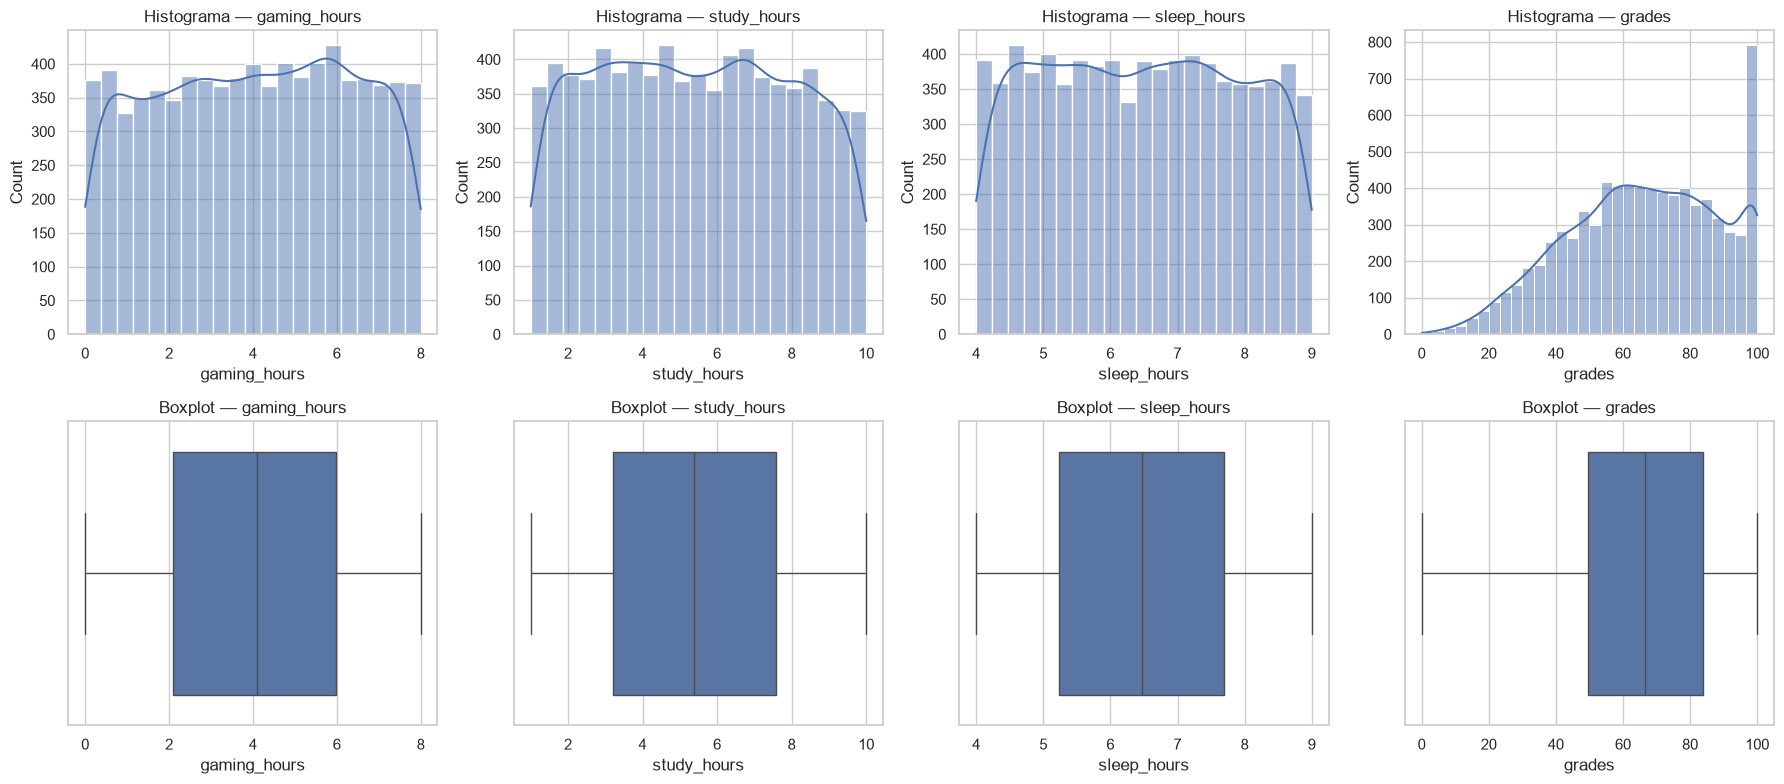

In [9]:
vars_principais = ["gaming_hours", "study_hours", "sleep_hours", "grades"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, col in enumerate(vars_principais):
    sns.histplot(df[col], kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"Histograma — {col}")
    sns.boxplot(x=df[col], ax=axes[1, i])
    axes[1, i].set_title(f"Boxplot — {col}")
plt.tight_layout()
plt.savefig("figuras/fig01_distribuicoes.png", dpi=150)
plt.show()

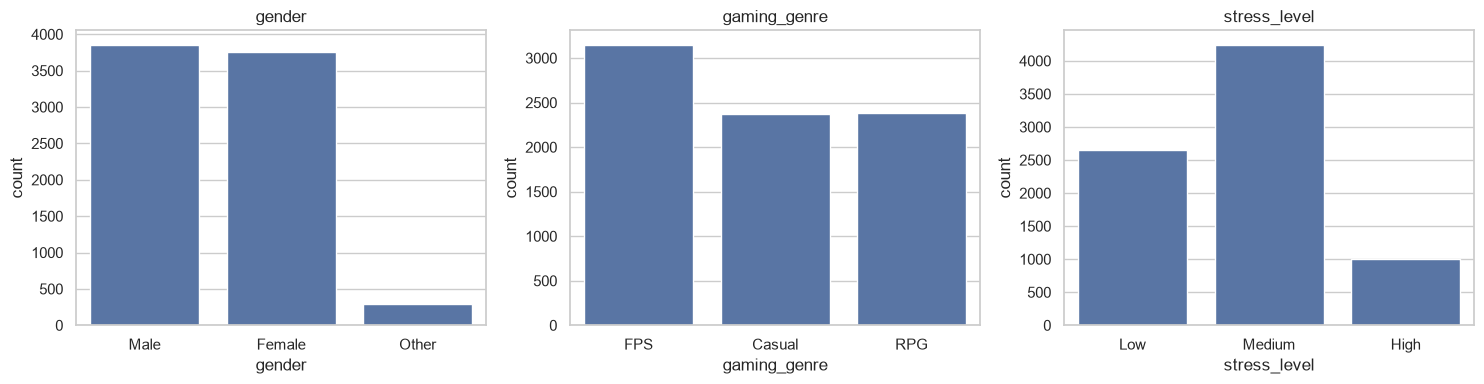

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["gender", "gaming_genre", "stress_level"]):
    ordem = ["Low", "Medium", "High"] if col == "stress_level" else None
    sns.countplot(data=df, x=col, order=ordem, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig("figuras/fig02_categoricas.png", dpi=150)
plt.show()

**Observações:** As horas de jogo (0 a 8h), de estudo (1 a 10h) e de sono (4 a 9h) apresentam distribuição aproximadamente uniforme, sem concentração em faixas específicas, e os boxplots não indicam outliers nessas variáveis. Esse padrão uniforme é mais um indício de dados simulados, já que hábitos reais tendem a se concentrar em torno de valores típicos.

As notas apresentam distribuição assimétrica, com maior concentração entre 50 e 85 (mediana próxima de 67) e um pico acentuado em 100. Esse pico indica um "efeito teto": muitos estudantes atingem a nota máxima, somando os valores originalmente iguais a 100 e as 134 notas acima de 100 que foram limitadas na etapa de pré-processamento.

Quanto às variáveis categóricas, os gêneros masculino e feminino estão equilibrados, enquanto a categoria "Other" é bem menor (cerca de 4%). Entre os gêneros de jogo, FPS é o mais frequente, e Casual e RPG têm quantidades semelhantes. No nível de estresse há desequilíbrio: Medium concentra a maior parte dos estudantes, seguido de Low, enquanto High é o grupo menos numeroso. Isso deve ser considerado nas comparações entre grupos.

## 7. Análise Exploratória: Correlações
Matriz de correlação de Pearson entre as variáveis numéricas, representada em mapa de calor, e ranking das variáveis mais associadas à nota.

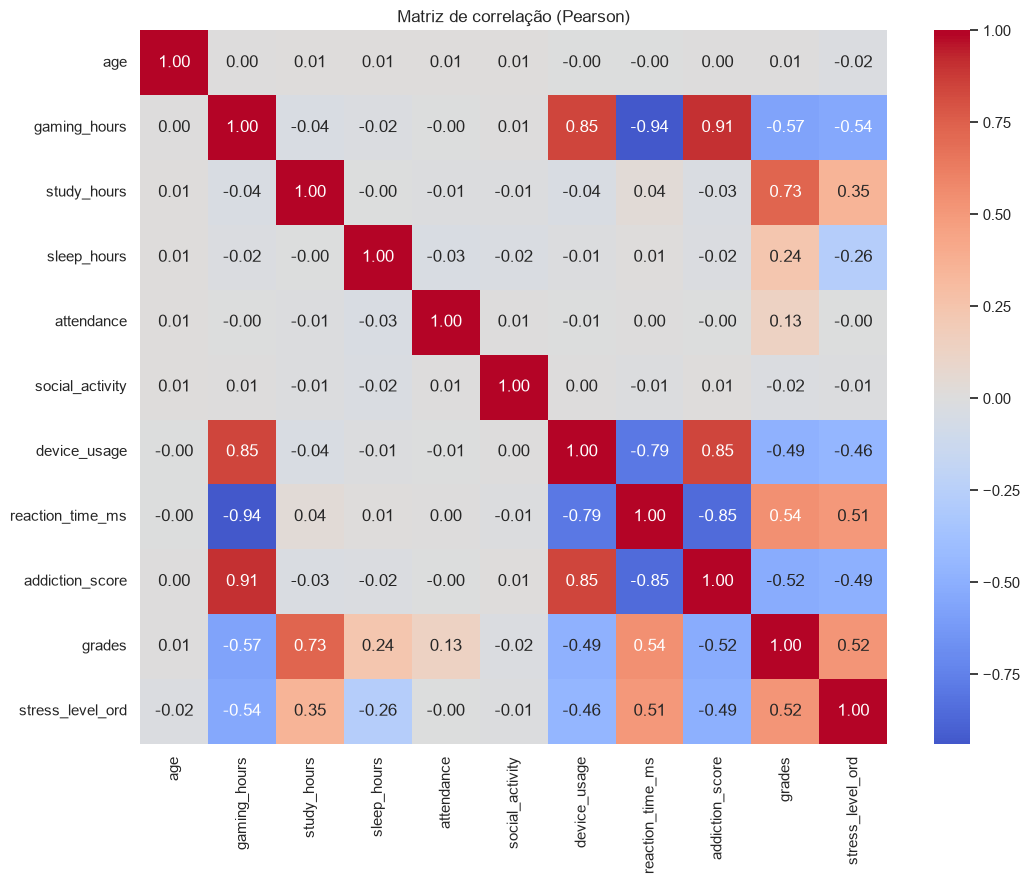

In [11]:
corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlação (Pearson)")
plt.tight_layout()
plt.savefig("figuras/fig03_correlacao.png", dpi=150)
plt.show()

In [12]:
print("Correlação de cada variável com a nota:")
print(corr["grades"].drop("grades").sort_values().round(3))
print("\nCorrelação jogo × sono:", round(corr.loc["gaming_hours", "sleep_hours"], 3))

Correlação de cada variável com a nota:
gaming_hours       -0.575
addiction_score    -0.518
device_usage       -0.490
social_activity    -0.020
age                 0.008
attendance          0.130
sleep_hours         0.241
stress_level_ord    0.518
reaction_time_ms    0.539
study_hours         0.731
Name: grades, dtype: float64

Correlação jogo × sono: -0.018


**Observações:** A variável mais associada à nota é o tempo de estudo, com correlação positiva forte (r = 0,731). As horas de jogo apresentam correlação negativa moderada com a nota (r = −0,575), acompanhadas do escore de dependência (r = −0,518) e do uso de dispositivos (r = −0,490), ambos também negativos.

A correlação entre horas de jogo e horas de sono é praticamente nula (r = −0,018), o que indica que a hipótese de mediação pelo sono não se sustenta: o sono tem alguma associação positiva com a nota (r = 0,241), mas não varia conforme o tempo de jogo.

Dois resultados chamam atenção: o nível de estresse tem correlação positiva com a nota (r = 0,518), ou seja, estudantes mais estressados tendem a ter notas maiores, e o tempo de reação também se associa positivamente à nota (r = 0,539). Uma possível explicação é que essas variáveis estejam ligadas a outros fatores: o estresse pode acompanhar mais horas de estudo, e o tempo de reação pode ser menor (mais rápido) entre quem joga mais. Essas hipóteses serão verificadas na etapa de regressão. Idade, atividade social e frequência têm associação fraca ou nula com a nota.

Lembrando que correlação indica associação, e não relação de causa e efeito.

## 8. Análise Exploratória — Relações com a nota
Gráficos de dispersão com linha de tendência (amostra de 2.000 registros, para evitar sobreposição excessiva de pontos) e comparação da nota entre grupos de estresse e gênero de jogo.

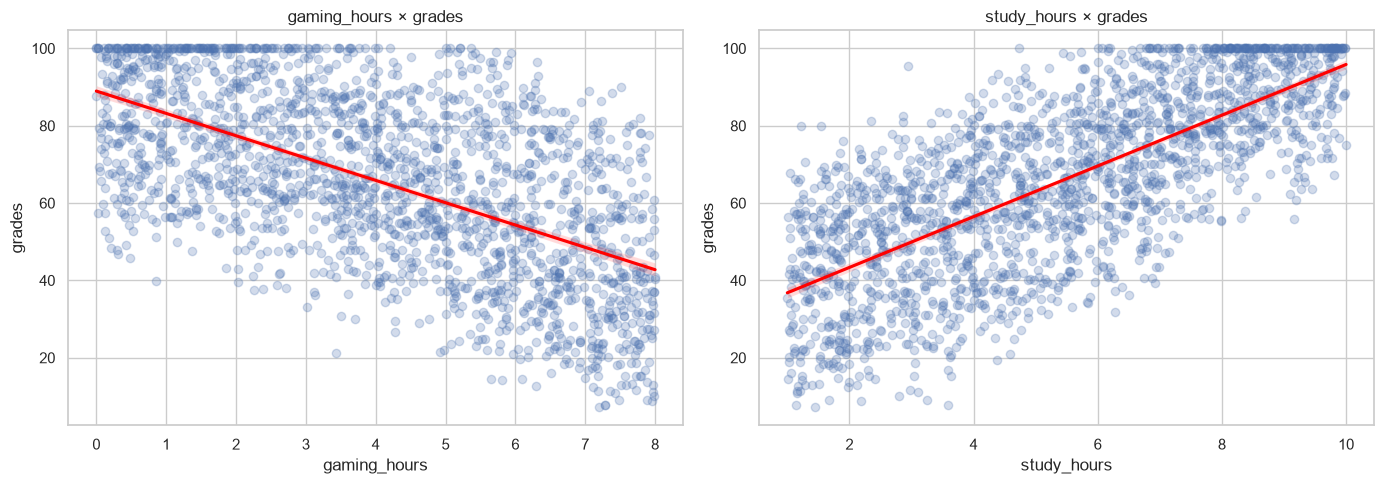

In [13]:
amostra = df.sample(2000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, x in zip(axes, ["gaming_hours", "study_hours"]):
    sns.regplot(data=amostra, x=x, y="grades", ax=ax,
                scatter_kws={"alpha": 0.25}, line_kws={"color": "red"})
    ax.set_title(f"{x} × grades")
plt.tight_layout()
plt.savefig("figuras/fig04_dispersao.png", dpi=150)
plt.show()

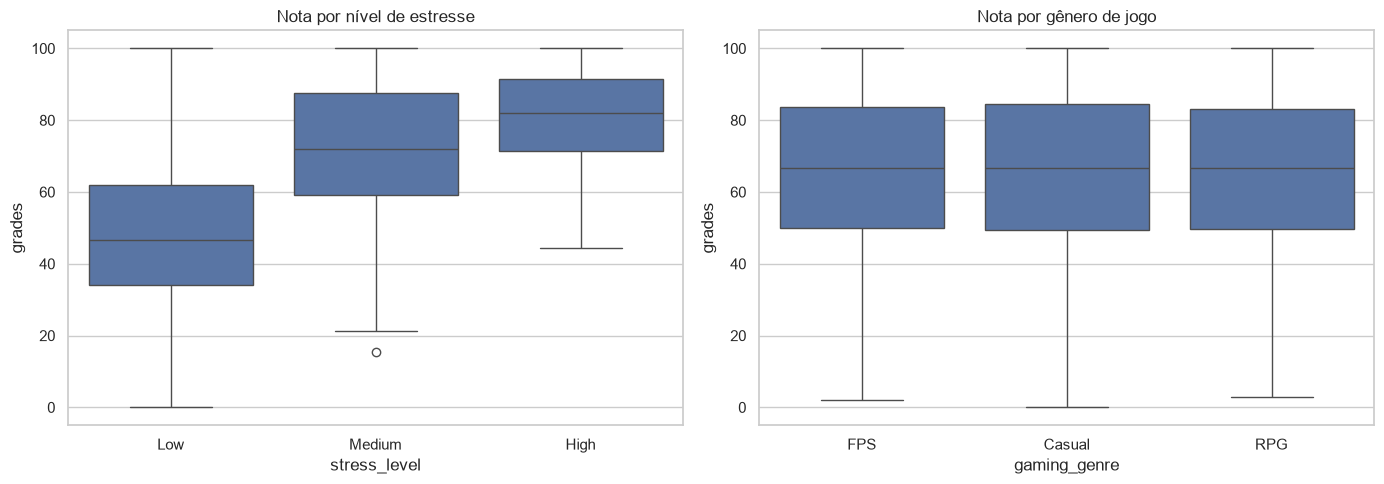

,mean,median,count
stress_level,,,
High,80.89,82.05,1010
Low,49.27,46.54,2645
Medium,72.62,72.08,4247


,mean,median,count
gaming_genre,,,
Casual,66.05,66.78,2372
FPS,65.87,66.56,3152
RPG,65.67,66.79,2378


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="stress_level", y="grades", order=["Low", "Medium", "High"], ax=axes[0])
axes[0].set_title("Nota por nível de estresse")
sns.boxplot(data=df, x="gaming_genre", y="grades", ax=axes[1])
axes[1].set_title("Nota por gênero de jogo")
plt.tight_layout()
plt.savefig("figuras/fig05_nota_por_grupo.png", dpi=150)
plt.show()

display(df.groupby("stress_level")["grades"].agg(["mean", "median", "count"]).round(2))
display(df.groupby("gaming_genre")["grades"].agg(["mean", "median", "count"]).round(2))

**Observações:** Os gráficos de dispersão confirmam as tendências observadas na matriz de correlação: a nota tende a cair à medida que aumentam as horas de jogo e a subir com mais horas de estudo. A relação é aproximadamente linear, mas com grande dispersão dos pontos, o que mostra que nenhuma variável sozinha explica a nota. Também é visível o efeito teto, com muitos estudantes concentrados na nota 100, principalmente entre os que jogam pouco ou estudam muito.

Na comparação por grupos, a nota aumenta com o nível de estresse: a média é de 49,27 no grupo Low, 72,62 no Medium e 80,89 no High, uma diferença de mais de 30 pontos entre os extremos. Já entre os gêneros de jogo não há diferença relevante: as médias são de 66,05 para Casual, 65,87 para FPS e 65,67 para RPG, com medianas e dispersões praticamente iguais. Isso sugere que o tipo de jogo não se relaciona com o desempenho, e sim a quantidade de tempo jogado.

## 9. Visualizações explicativas
A partir da exploração, selecionamos quatro gráficos para comunicar os principais achados, seguindo um padrão visual único: título que afirma o achado, subtítulo com a população e o n, eixos em português, uma cor de destaque e a fonte no rodapé. Cada gráfico responde a uma pergunta do projeto.

In [15]:
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

DESTAQUE = "#D78438"
CINZA = "#B9BEC6"
FONTE = "Fonte: Kaggle, Gaming vs Academic Performance (aiexplorer77). Dados simulados."

def br(valor, casas=1):
    """Formata número com vírgula decimal."""
    return f"{valor:.{casas}f}".replace(".", ",")

def milhar(n):
    """Formata inteiro com ponto de milhar: 7902 -> 7.902"""
    return f"{n:,}".replace(",", ".")

def finalizar(ax, titulo, subtitulo, arquivo, fonte=FONTE):
    ax.figure.suptitle(titulo, x=0.02, ha="left", fontsize=14, fontweight="bold")
    ax.set_title(subtitulo, loc="left", fontsize=11, color="gray")
    ax.figure.text(0.02, 0.01, fonte, fontsize=8, color="gray")
    ax.figure.tight_layout(rect=(0, 0.04, 1, 0.97))
    ax.figure.savefig(f"figuras/{arquivo}.png", dpi=200)
    plt.show()

rotulos = {
    "study_hours": "Horas de estudo", "gaming_hours": "Horas de jogo",
    "sleep_hours": "Horas de sono", "addiction_score": "Escore de dependência",
    "device_usage": "Uso de dispositivos", "stress_level_ord": "Nível de estresse",
    "reaction_time_ms": "Tempo de reação", "attendance": "Frequência",
    "social_activity": "Atividade social", "age": "Idade",
}

**Pergunta 1:** Quais fatores mais se associam à nota?

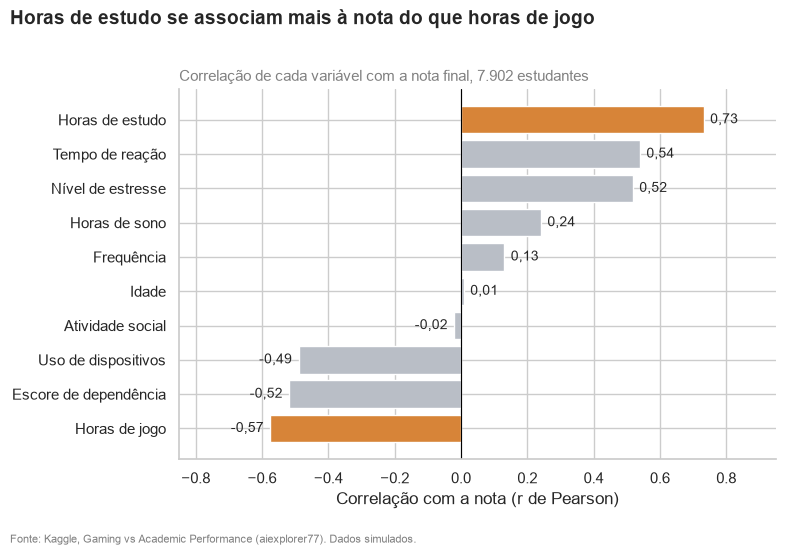

In [16]:
r = corr["grades"].drop("grades").sort_values()
cores = [DESTAQUE if v in ("study_hours", "gaming_hours") else CINZA for v in r.index]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh([rotulos.get(v, v) for v in r.index], r.values, color=cores)
for i, v in enumerate(r.values):
    ax.text(v + (0.02 if v >= 0 else -0.02), i, br(v, 2), va="center",
            ha="left" if v >= 0 else "right", fontsize=10)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-0.85, 0.95)
ax.set_xlabel("Correlação com a nota (r de Pearson)")
finalizar(ax, "Horas de estudo se associam mais à nota do que horas de jogo",
          f"Correlação de cada variável com a nota final, {milhar(len(df))} estudantes",
          "av1_01_correlacoes")

**Leitura:** Entre os 7.902 estudantes, as horas de estudo têm a associação mais forte com a nota (r = 0,73), acima das horas de jogo, que se associam negativamente (r = −0,57). Como a análise é correlacional, o gráfico indica associação, e não causa.

**Pergunta 2:** Como a nota acompanha as horas de jogo?

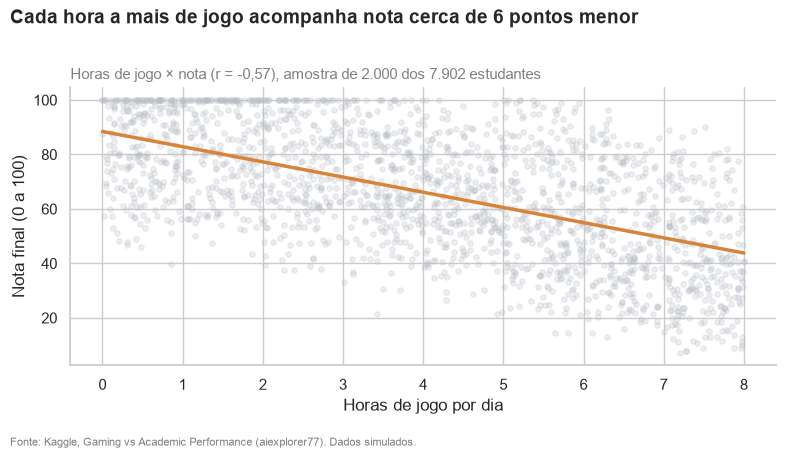

In [17]:
amostra = df.sample(2000, random_state=42)
r_jogo = df["gaming_hours"].corr(df["grades"])
coef = np.polyfit(df["gaming_hours"], df["grades"], 1)

fig, ax = plt.subplots()
ax.scatter(amostra["gaming_hours"], amostra["grades"], alpha=0.25, s=15, color=CINZA)
x = np.linspace(0, 8, 100)
ax.plot(x, np.polyval(coef, x), color=DESTAQUE, lw=2.5)
ax.set_xlabel("Horas de jogo por dia")
ax.set_ylabel("Nota final (0 a 100)")
finalizar(ax, f"Cada hora a mais de jogo acompanha nota cerca de {abs(coef[0]):.0f} pontos menor",
          f"Horas de jogo × nota (r = {br(r_jogo, 2)}), amostra de 2.000 dos {milhar(len(df))} estudantes",
          "av1_02_jogo_nota")

**Leitura:** A nota tende a diminuir conforme aumentam as horas de jogo, em uma relação aproximadamente linear, mas com grande dispersão: estudantes que jogam o mesmo tempo têm notas muito diferentes, o que indica que outros fatores também pesam.

**Pergunta 3:** A nota é diferente entre os níveis de estresse?

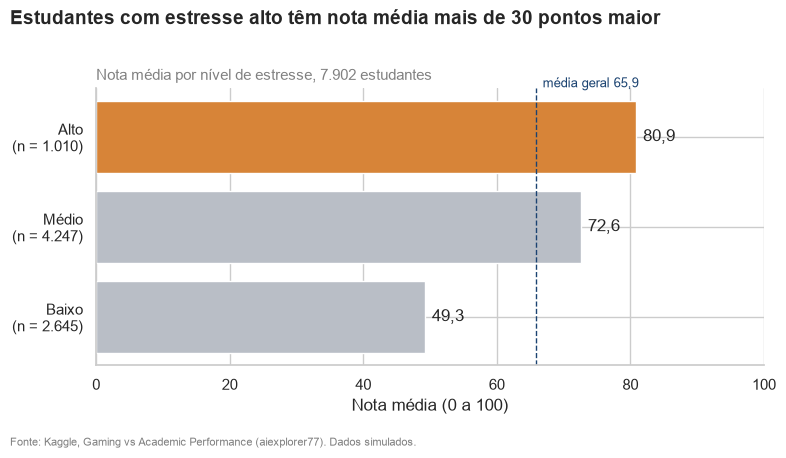

In [18]:
ordem = ["Low", "Medium", "High"]
nomes = {"Low": "Baixo", "Medium": "Médio", "High": "Alto"}
res = df.groupby("stress_level")["grades"].agg(n="size", media="mean").reindex(ordem)
media_geral = df["grades"].mean()

fig, ax = plt.subplots()
rot = [f"{nomes[s]}\n(n = {milhar(n)})" for s, n in res["n"].items()]
ax.barh(rot, res["media"], color=[DESTAQUE if s == "High" else CINZA for s in res.index])
for i, m in enumerate(res["media"]):
    ax.text(m + 1, i, br(m), va="center")
ax.axvline(media_geral, ls="--", lw=1, color="#1B4371")
ax.text(media_geral + 1, len(res) - 0.45, f"média geral {br(media_geral)}", fontsize=9, color="#1B4371")
ax.set_xlim(0, 100)
ax.set_xlabel("Nota média (0 a 100)")
finalizar(ax, "Estudantes com estresse alto têm nota média mais de 30 pontos maior",
          f"Nota média por nível de estresse, {milhar(len(df))} estudantes",
          "av1_03_nota_estresse")

**Leitura:** A nota média é de 80,9 entre os estudantes com estresse alto, contra 49,3 entre os de estresse baixo. O resultado é contraintuitivo e pode estar ligado a outras variáveis, como as horas de estudo, o que será investigado na etapa de regressão. O grupo de estresse alto é o menor (n = 1.010).

**Pergunta 4:** Quanto a preparação alterou a base?

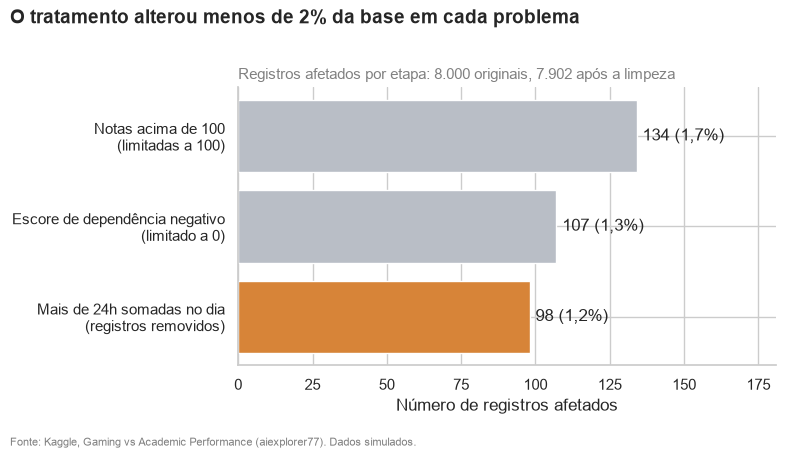

In [19]:
etapas = ["Notas acima de 100\n(limitadas a 100)",
          "Escore de dependência negativo\n(limitado a 0)",
          "Mais de 24h somadas no dia\n(registros removidos)"]
valores = [n_acima, n_neg, n_24h]
total = len(df_original)

fig, ax = plt.subplots()
ax.barh(etapas, valores, color=[CINZA, CINZA, DESTAQUE])
for i, v in enumerate(valores):
    ax.text(v + 2, i, f"{v} ({br(v / total * 100)}%)", va="center")
ax.set_xlim(0, max(valores) * 1.35)
ax.invert_yaxis()
ax.set_xlabel("Número de registros afetados")
finalizar(ax, "O tratamento alterou menos de 2% da base em cada problema",
          f"Registros afetados por etapa: {milhar(total)} originais, {milhar(len(df))} após a limpeza",
          "av1_04_preparacao")

**Leitura:** Três inconsistências foram tratadas, cada uma afetando menos de 2% da base. Notas e escores fora da escala foram limitados aos valores válidos, preservando os registros. Já os casos com mais de 24 horas diárias foram removidos, por não ser possível identificar qual variável estava incorreta. A base passou de 8.000 para 7.902 registros.

## 10. Conclusões parciais e próximas etapas
**Achados até aqui:**
- O tempo de estudo é o fator mais associado à nota (r = 0,731), acima do tempo de jogo (r = −0,575). A mensagem prática tende a ser "garantir horas de estudo", e não apenas "proibir o jogo".
- O escore de dependência (r = −0,518) e o uso de dispositivos (r = −0,490) também se associam negativamente à nota.
- Jogo e sono não estão correlacionados (r = −0,018), então a hipótese de mediação pelo sono não se sustenta.
- O gênero de jogo não apresenta relação com a nota.
- O estresse apresentou associação positiva com a nota (r = 0,518), um resultado contraintuitivo que precisa ser investigado.

**Limitações:** a própria descrição do dataset informa que os dados são simulados, o que é reforçado pelas notas acima de 100, escores de dependência negativos, registros com mais de 24h diárias e distribuições uniformes. Os resultados servem como exercício analítico e não podem ser generalizados. A análise é correlacional, não causal.

**Próximas etapas:**
- Comparar grupos por faixa de horas de jogo (leve, moderado e excessivo) para verificar se existe um "ponto de virada".
- Investigar se a associação positiva do estresse e do tempo de reação com a nota se explica por outras variáveis (como horas de estudo e de jogo).
- Testar estresse, sono e addiction_score como mediadores, com regressões com e sem essas variáveis.
- Construir um modelo de regressão para estimar o peso relativo de cada fator na nota.
- Elaborar as visualizações finais e a apresentação.